In [24]:
from ast import parse

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from numpy.ma.core import max_val

from scipy.stats import poisson



all_matches = pd.read_csv("../data/processed/matches.csv", parse_dates=["date"], dtype={"season":str})
all_matches.shape
all_matches.head(5)


,date,Home_team,Away_team,Home_goals,Away_goals,Result,Home_odd,Draw_odd,Away_odd,season
0,2018-08-10,Man United,Leicester,2,1,H,1.57,3.9,7.50,1819
1,2018-08-11,Bournemouth,Cardiff,2,0,H,1.90,3.6,4.50,1819
2,2018-08-11,Fulham,Crystal Palace,0,2,A,2.50,3.4,3.00,1819
3,2018-08-11,Huddersfield,Chelsea,0,3,A,6.50,4.0,1.61,1819
4,2018-08-11,Newcastle,Tottenham,1,2,A,3.90,3.5,2.04,1819


Text(0.5, 1.0, 'Percent of possibilities')

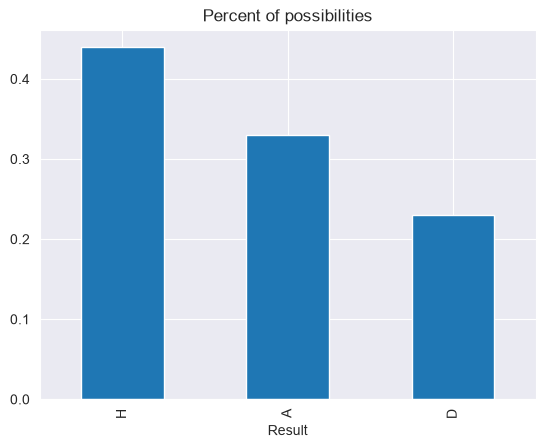

In [25]:
all_matches.value_counts("Result", normalize=True).plot(kind = "bar")
plt.title("Percent of possibilities")

In season 20/21 we can see that the away teams win more matches than home team, it might be connected to pancdemic conditions when stadiums were empty


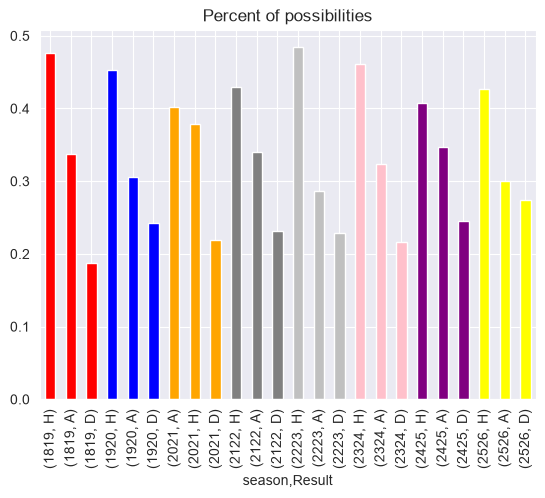

In [26]:
import matplotlib.pyplot as plt

# 1. Pobieramy dane
data = all_matches.groupby("season")["Result"].value_counts(normalize=True)


colors_dict = {
    "1819" : "red",
    "1920" : "blue",
    "2021" : "orange",
    "2122" : "grey",
    "2223" : "silver",
    "2324" : "pink",
    "2425" : "purple",
    "2526" : "yellow"
}

colors_list = data.index.get_level_values("season").astype(str).map(colors_dict)

# 3. Rysowanie wykresu
data.plot(kind="bar", color=colors_list)
plt.title("Percent of possibilities")
plt.show()



In [27]:
all_matches.groupby("season")["Result"].value_counts( normalize=True).unstack()[["H", "D", "A"]]


Result,H,D,A
season,,,
1819,0.476316,0.186842,0.336842
1920,0.452632,0.242105,0.305263
2021,0.378947,0.218421,0.402632
2122,0.428947,0.231579,0.339474
2223,0.484211,0.228947,0.286842
2324,0.460526,0.215789,0.323684
2425,0.407895,0.244737,0.347368
2526,0.426316,0.273684,0.300000


In [28]:
all_matches.groupby("season")["Home_goals"].mean()


season
1819    1.568421
1920    1.515789
2021    1.352632
2122    1.513158
2223    1.634211
2324    1.800000
2425    1.513158
2526    1.526316
Name: Home_goals, dtype: float64

Away teams scored on average less goals than home teams


In [47]:
home_mean = all_matches["Home_goals"].mean()
away_mean = all_matches["Away_goals"].mean()

home_mean


np.float64(1.5529605263157895)

In [30]:
away_mean

np.float64(1.305921052631579)

In [31]:
mean_goals = all_matches.groupby("season")[["Home_goals", "Away_goals"]].mean()
mean_goals

,Home_goals,Away_goals
season,,
1819,1.568421,1.252632
1920,1.515789,1.205263
2021,1.352632,1.342105
2122,1.513158,1.305263
2223,1.634211,1.218421
2324,1.800000,1.478947
2425,1.513158,1.421053
2526,1.526316,1.223684


In [32]:
mean_goals["difference"] = mean_goals["Home_goals"] - mean_goals["Away_goals"]
mean_goals

,Home_goals,Away_goals,difference
season,,,
1819,1.568421,1.252632,0.315789
1920,1.515789,1.205263,0.310526
2021,1.352632,1.342105,0.010526
2122,1.513158,1.305263,0.207895
2223,1.634211,1.218421,0.415789
2324,1.800000,1.478947,0.321053
2425,1.513158,1.421053,0.092105
2526,1.526316,1.223684,0.302632


On average Home teams score 0.2470 goals more than Away teams

In [33]:
mean_goals["difference"].min()

np.float64(0.010526315789473717)

In [14]:
mean_goals["difference"].mean()

np.float64(0.2470394736842106)

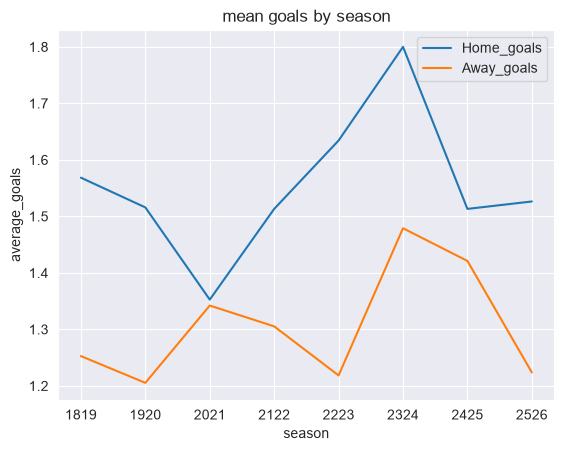

In [34]:
mean_goals[["Home_goals", "Away_goals"]].plot(kind="line")
plt.title("mean goals by season")
plt.xlabel("season")
plt.ylabel("average_goals")
plt.show()

In [40]:
empirical_home = all_matches.value_counts("Home_goals", normalize=True).sort_index()
empirical_home

Home_goals
0    0.231250
1    0.314145
2    0.243421
3    0.130921
4    0.053618
5    0.019408
6    0.004605
7    0.001645
8    0.000329
9    0.000658
Name: proportion, dtype: float64

In [41]:
empirical_away = all_matches.value_counts("Away_goals", normalize=True).sort_index()
empirical_away

Away_goals
0    0.290461
1    0.337500
2    0.222697
3    0.098026
4    0.033882
5    0.013158
6    0.003289
7    0.000329
8    0.000329
9    0.000329
Name: proportion, dtype: float64

In [61]:
max_goals = max(all_matches["Home_goals"].max(), all_matches["Away_goals"].max())

In [62]:
lam_home = home_mean # lambda home

k = range(0, max_goals + 1)

theoretical_home = poisson.pmf(k, lam_home)
print(f"lambda = (home team goals average):  {lam_home:.3f}")
theoretical_home


lambda = (home team goals average):  1.553


array([2.11620537e-01, 3.28638341e-01, 2.55181186e-01, 1.32095436e-01,
       5.12847495e-02, 1.59286383e-02, 4.12275776e-03, 9.14640008e-04,
       1.77549978e-04, 3.06364564e-05])

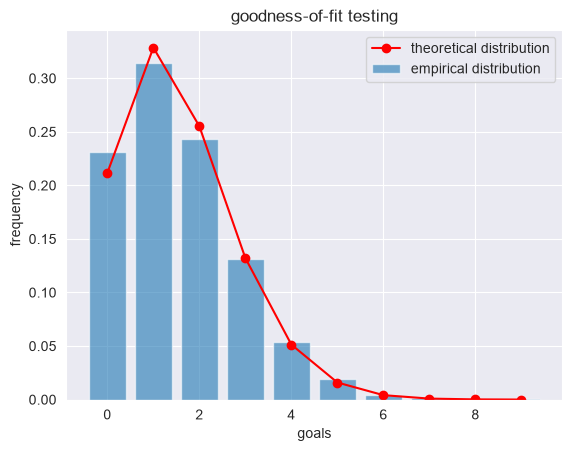

In [63]:
plt.bar(empirical_home.index, empirical_home.values, alpha = 0.6, label = 'empirical distribution')
plt.plot(k, theoretical_home, marker = "o", color = "red", label = "theoretical distribution" )
plt.title("goodness-of-fit testing")
plt.xlabel("goals")
plt.ylabel("frequency")
plt.legend()
plt.show()

In [ ]:
def plot_poisson_fit(goals, title):
